In [3]:
import pandas as pd
import numpy as np
import os

# Load original datasets
movies = pd.read_csv("../data/raw/movies.csv")
ratings = pd.read_csv("../data/raw/ratings.csv")
tags = pd.read_csv("../data/raw/tags.csv")
links = pd.read_csv("../data/raw/links.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [5]:
print("Movies:", movies.shape)
print("Ratings:", ratings.shape)
print("Tags:", tags.shape)
print("Links:", links.shape)

Movies: (9742, 3)
Ratings: (100836, 4)
Tags: (3683, 4)
Links: (9742, 3)


In [7]:
movies_clean = movies.copy()
ratings_clean = ratings.copy()
tags_clean = tags.copy()
links_clean = links.copy()

print("Working datasets created successfully!")

Working datasets created successfully!


In [9]:
datasets = {
    "Movies": movies_clean,
    "Ratings": ratings_clean,
    "Tags": tags_clean,
    "Links": links_clean
}

for name, df in datasets.items():
    print(f"\n{'='*40}")
    print(f"{name}")
    print(f"{'='*40}")
    print("Shape:", df.shape)
    print("\nData Types:")
    print(df.dtypes)
    print("\nFirst 3 rows:")
    display(df.head(3))


Movies
Shape: (9742, 3)

Data Types:
movieId     int64
title      object
genres     object
dtype: object

First 3 rows:


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance



Ratings
Shape: (100836, 4)

Data Types:
userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object

First 3 rows:


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224



Tags
Shape: (3683, 4)

Data Types:
userId        int64
movieId       int64
tag          object
timestamp     int64
dtype: object

First 3 rows:


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992



Links
Shape: (9742, 3)

Data Types:
movieId      int64
imdbId       int64
tmdbId     float64
dtype: object

First 3 rows:


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0


In [11]:
print("Number of unique users:", ratings_clean["userId"].nunique())
print("Number of unique movies:", ratings_clean["movieId"].nunique())

print("Number of unique movies in Movies:", movies_clean["movieId"].nunique())
print("Number of unique users in Ratings:", ratings_clean["userId"].nunique())

Number of unique users: 610
Number of unique movies: 9724
Number of unique movies in Movies: 9742
Number of unique users in Ratings: 610


In [13]:
movies_clean["title"].sample(15, random_state=42)

6213                    Notorious Bettie Page, The (2005)
1056               Star Trek V: The Final Frontier (1989)
4891                               Starsky & Hutch (2004)
346                            Colonel Chabert, Le (1994)
5353                             Country Girl, The (1954)
7829                                Civil War, The (1990)
8655                     John Mulaney: New In Town (2012)
9056                              Saving Christmas (2014)
1111                                 Kolya (Kolja) (1996)
7278                           Alice in Wonderland (2010)
6578                                  Mr. Woodcock (2007)
1730           Life Is Beautiful (La Vita è bella) (1997)
2732                                    Stay Tuned (1992)
367                                     Blown Away (1994)
2742    Decline of Western Civilization Part II: The M...
Name: title, dtype: object

In [15]:
# Extract movie release year
movies_clean["year"] = movies_clean["title"].str.extract(
    r'\((\d{4})\)$'
)

# Convert year to numeric
movies_clean["year"] = pd.to_numeric(
    movies_clean["year"],
    errors="coerce"
).astype("Int64")

# Create title without release year
movies_clean["title_without_year"] = movies_clean["title"].str.replace(
    r'\s*\(\d{4}\)$',
    '',
    regex=True
)

# Display results
display(movies_clean[["title", "title_without_year", "year"]].head(15))

,title,title_without_year,year
0,Toy Story (1995),Toy Story,1995
1,Jumanji (1995),Jumanji,1995
2,Grumpier Old Men (1995),Grumpier Old Men,1995
3,Waiting to Exhale (1995),Waiting to Exhale,1995
4,Father of the Bride Part II (1995),Father of the Bride Part II,1995
5,Heat (1995),Heat,1995
6,Sabrina (1995),Sabrina,1995
7,Tom and Huck (1995),Tom and Huck,1995
8,Sudden Death (1995),Sudden Death,1995
9,GoldenEye (1995),GoldenEye,1995


In [17]:
print("Missing release years:", movies_clean["year"].isnull().sum())

print("\nYear statistics:")
print(movies_clean["year"].describe())

print("\nMovies without extracted year:")
display(
    movies_clean[movies_clean["year"].isnull()][["title"]].head(10)
)

Missing release years: 24

Year statistics:
count         9718.0
mean     1994.603931
std        18.539602
min           1902.0
25%           1988.0
50%           1999.0
75%           2008.0
max           2018.0
Name: year, dtype: Float64

Movies without extracted year:


,title
5609,From Dusk Till Dawn 2: Texas Blood Money (1999)
6059,Babylon 5
6706,Justice League: The New Frontier (2008)
6718,Assembly (Ji jie hao) (2007)
7878,96 Minutes (2011)
7896,Superman/Doomsday (2007)
7910,Pocahontas II: Journey to a New World (1998)
7978,Runaway Brain (1995)
8148,Justice League: Doom (2012)
8228,3 dev adam (Three Giant Men) (1973)


In [19]:
# Inspect titles with missing extracted years
missing_years = movies_clean[
    movies_clean["year"].isnull()
]

for title in missing_years["title"]:
    print(repr(title))

'From Dusk Till Dawn 2: Texas Blood Money (1999) '
'Babylon 5'
'Justice League: The New Frontier (2008) '
'Assembly (Ji jie hao) (2007) '
'96 Minutes (2011) '
'Superman/Doomsday (2007) '
'Pocahontas II: Journey to a New World (1998) '
'Runaway Brain (1995) '
'Justice League: Doom (2012) '
'3 dev adam (Three Giant Men) (1973) '
'Guilty of Romance (Koi no tsumi) (2011) '
'Dead Snow 2: Red vs. Dead (2014) '
'Ready Player One'
'Hyena Road'
'The Adventures of Sherlock Holmes and Doctor Watson'
'Nocturnal Animals'
'Paterson'
'Moonlight'
'The OA'
'Cosmos'
'Maria Bamford: Old Baby'
'Death Note: Desu nôto (2006–2007)'
'Generation Iron 2'
'Black Mirror'


In [21]:
# Extract year, allowing trailing whitespace
movies_clean["year"] = movies_clean["title"].str.extract(
    r'\((\d{4})\)\s*$'
)

movies_clean["year"] = pd.to_numeric(
    movies_clean["year"],
    errors="coerce"
).astype("Int64")

# Remove year and trailing whitespace
movies_clean["title_without_year"] = movies_clean["title"].str.replace(
    r'\s*\(\d{4}\)\s*$',
    '',
    regex=True
).str.strip()

In [23]:
print("Missing release years:", movies_clean["year"].isnull().sum())

display(
    movies_clean[movies_clean["year"].isnull()][["title"]]
)

Missing release years: 13


,title
6059,Babylon 5
9031,Ready Player One
9091,Hyena Road
9138,The Adventures of Sherlock Holmes and Doctor W...
9179,Nocturnal Animals
9259,Paterson
9367,Moonlight
9448,The OA
9514,Cosmos
9515,Maria Bamford: Old Baby


In [25]:
print("Total movies:", len(movies_clean))
print("Extracted years:", movies_clean["year"].notna().sum())
print("Missing years:", movies_clean["year"].isna().sum())

print("\nYear range:")
print(movies_clean["year"].min(), "-", movies_clean["year"].max())

print("\nSample of processed movies:")
display(
    movies_clean[
        ["movieId", "title", "title_without_year", "year"]
    ].sample(10, random_state=42)
)

Total movies: 9742
Extracted years: 9729
Missing years: 13

Year range:
1902 - 2018

Sample of processed movies:


,movieId,title,title_without_year,year
6213,45635,"Notorious Bettie Page, The (2005)","Notorious Bettie Page, The",2005
1056,1373,Star Trek V: The Final Frontier (1989),Star Trek V: The Final Frontier,1989
4891,7325,Starsky & Hutch (2004),Starsky & Hutch,2004
346,389,"Colonel Chabert, Le (1994)","Colonel Chabert, Le",1994
5353,8920,"Country Girl, The (1954)","Country Girl, The",1954
7829,93040,"Civil War, The (1990)","Civil War, The",1990
8655,120807,John Mulaney: New In Town (2012),John Mulaney: New In Town,2012
9056,141994,Saving Christmas (2014),Saving Christmas,2014
1111,1446,Kolya (Kolja) (1996),Kolya (Kolja),1996
7278,74789,Alice in Wonderland (2010),Alice in Wonderland,2010


In [27]:
# Extract all unique genres
unique_genres = set()

for genres in movies_clean["genres"]:
    unique_genres.update(genres.split("|"))

print("Number of unique genres:", len(unique_genres))
print("\nUnique genres:")
print(sorted(unique_genres))

Number of unique genres: 20

Unique genres:
['(no genres listed)', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']


In [29]:
from collections import Counter

genre_counts = Counter()

for genres in movies_clean["genres"]:
    genre_counts.update(genres.split("|"))

genre_distribution = pd.DataFrame(
    genre_counts.items(),
    columns=["Genre", "Movie_Count"]
).sort_values(
    by="Movie_Count",
    ascending=False
)

display(genre_distribution)

,Genre,Movie_Count
6,Drama,4361
3,Comedy,3756
9,Thriller,1894
7,Action,1828
5,Romance,1596
0,Adventure,1263
8,Crime,1199
12,Sci-Fi,980
10,Horror,978
4,Fantasy,779


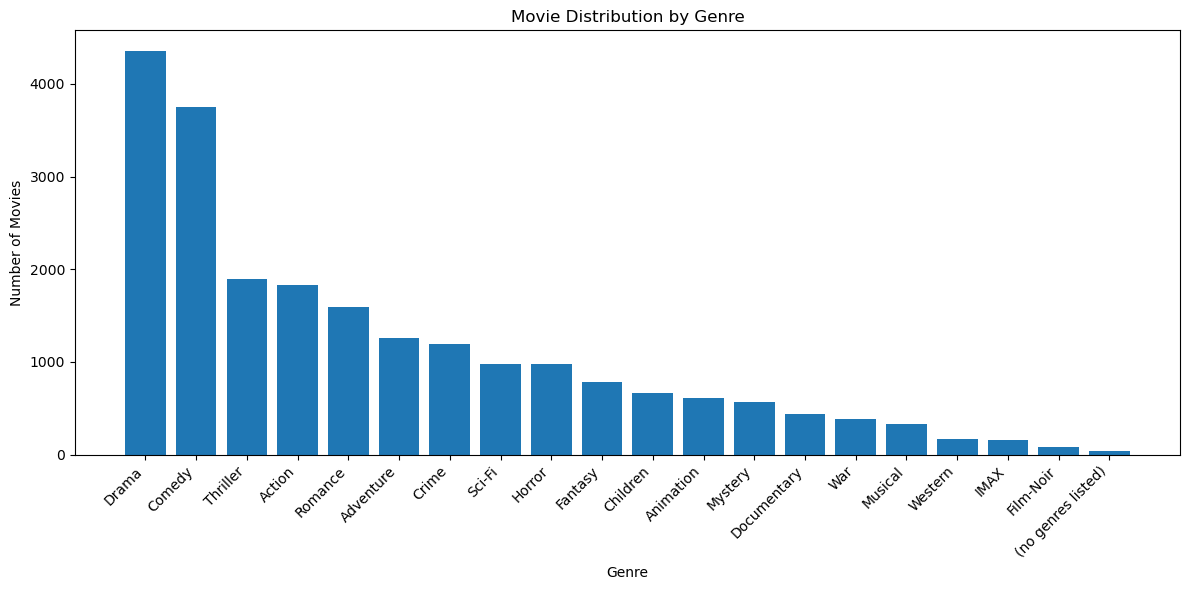

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    genre_distribution["Genre"],
    genre_distribution["Movie_Count"]
)

plt.title("Movie Distribution by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [33]:
# Remove the special category from the genre list
movies_clean["genres_list"] = movies_clean["genres"].apply(
    lambda x: [] if x == "(no genres listed)" else x.split("|")
)

# Apply Multi-Hot Encoding
genres_encoded = movies_clean["genres_list"].str.join("|").str.get_dummies(sep="|")

# Add encoded genres to movies_clean
movies_clean = pd.concat(
    [movies_clean, genres_encoded],
    axis=1
)

print("Multi-Hot Encoding completed!")
print("New dataset shape:", movies_clean.shape)

display(movies_clean.head())

Multi-Hot Encoding completed!
New dataset shape: (9742, 25)


,movieId,title,genres,year,title_without_year,genres_list,Action,Adventure,Animation,Children,...,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995,Toy Story,"[Adventure, Animation, Children, Comedy, Fantasy]",0,1,1,1,...,0,0,0,0,0,0,0,0,0,0
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995,Jumanji,"[Adventure, Children, Fantasy]",0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
2,3,Grumpier Old Men (1995),Comedy|Romance,1995,Grumpier Old Men,"[Comedy, Romance]",0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995,Waiting to Exhale,"[Comedy, Drama, Romance]",0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
4,5,Father of the Bride Part II (1995),Comedy,1995,Father of the Bride Part II,[Comedy],0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [35]:
# Check encoded genres
genre_columns = sorted(unique_genres - {"(no genres listed)"})

display(
    movies_clean[
        ["title", "genres"] + genre_columns
    ].head(10)
)

# Check number of genre columns
print("Number of encoded genre columns:", len(genre_columns))

# Check movies without genres
print(
    "Movies without genres:",
    (movies_clean[genre_columns].sum(axis=1) == 0).sum()
)

,title,genres,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,...,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,0,1,1,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Jumanji (1995),Adventure|Children|Fantasy,0,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,Grumpier Old Men (1995),Comedy|Romance,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,Waiting to Exhale (1995),Comedy|Drama|Romance,0,0,0,0,1,0,0,1,...,0,0,0,0,0,1,0,0,0,0
4,Father of the Bride Part II (1995),Comedy,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,Heat (1995),Action|Crime|Thriller,1,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
6,Sabrina (1995),Comedy|Romance,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0
7,Tom and Huck (1995),Adventure|Children,0,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,Sudden Death (1995),Action,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,GoldenEye (1995),Action|Adventure|Thriller,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


Number of encoded genre columns: 19
Movies without genres: 34


In [37]:
print(movies_clean.columns.tolist())
print("\nTotal columns:", len(movies_clean.columns))

['movieId', 'title', 'genres', 'year', 'title_without_year', 'genres_list', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']

Total columns: 25


In [39]:
# Convert Unix timestamp to datetime
ratings_clean["timestamp"] = pd.to_datetime(
    ratings_clean["timestamp"],
    unit="s"
)

# Verify conversion
print(ratings_clean["timestamp"].dtype)

display(ratings_clean.head())

datetime64[ns]


,userId,movieId,rating,timestamp
0,1,1,4.0,2000-07-30 18:45:03
1,1,3,4.0,2000-07-30 18:20:47
2,1,6,4.0,2000-07-30 18:37:04
3,1,47,5.0,2000-07-30 19:03:35
4,1,50,5.0,2000-07-30 18:48:51


In [41]:
# Extract temporal features
ratings_clean["rating_year"] = ratings_clean["timestamp"].dt.year

ratings_clean["rating_month"] = ratings_clean["timestamp"].dt.month

ratings_clean["rating_dayofweek"] = ratings_clean["timestamp"].dt.dayofweek

display(ratings_clean.head())

,userId,movieId,rating,timestamp,rating_year,rating_month,rating_dayofweek
0,1,1,4.0,2000-07-30 18:45:03,2000,7,6
1,1,3,4.0,2000-07-30 18:20:47,2000,7,6
2,1,6,4.0,2000-07-30 18:37:04,2000,7,6
3,1,47,5.0,2000-07-30 19:03:35,2000,7,6
4,1,50,5.0,2000-07-30 18:48:51,2000,7,6


In [43]:
print("Rating statistics:")
display(ratings_clean["rating"].describe())

print("\nUnique rating values:")
print(sorted(ratings_clean["rating"].unique()))

Rating statistics:


count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64


Unique rating values:
[0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]


In [45]:
print("Missing values:")
print(ratings_clean.isnull().sum())

Missing values:
userId              0
movieId             0
rating              0
timestamp           0
rating_year         0
rating_month        0
rating_dayofweek    0
dtype: int64


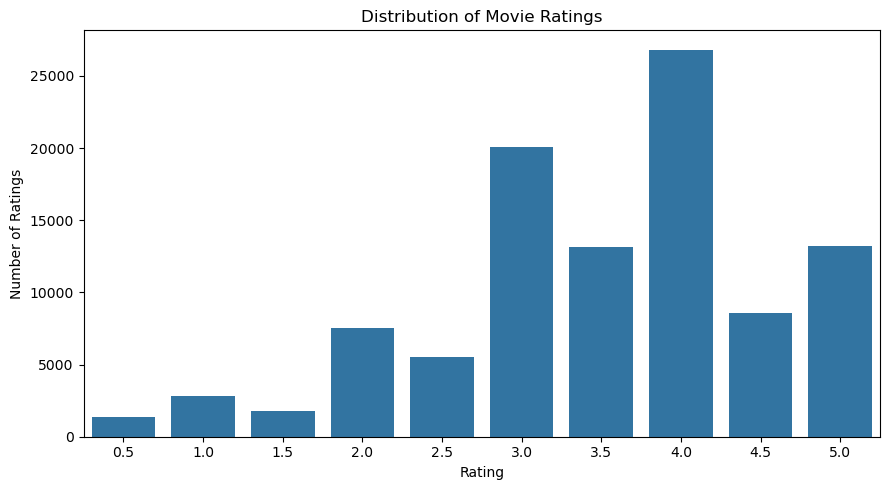

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=ratings_clean,
    x="rating"
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.tight_layout()
plt.show()

In [49]:
rating_distribution = (
    ratings_clean["rating"]
    .value_counts()
    .sort_index()
)

display(rating_distribution)

rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64

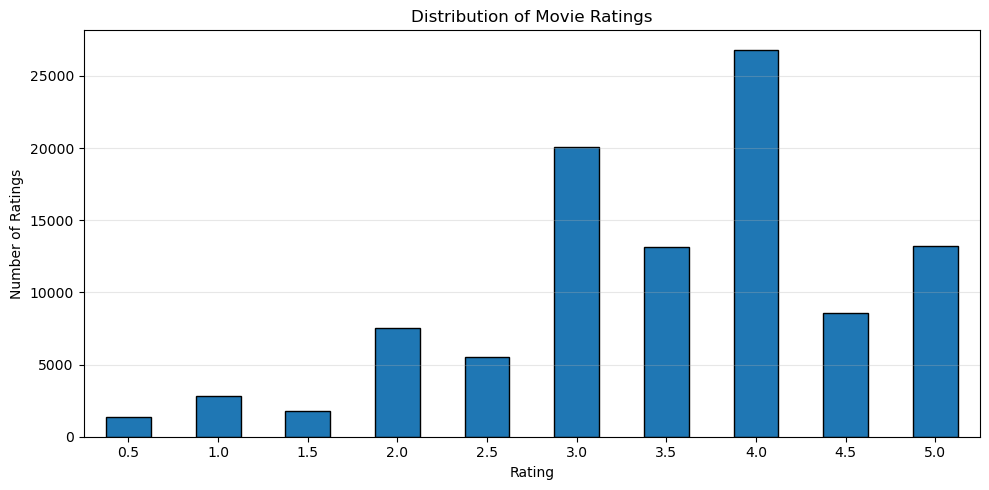

In [51]:
plt.figure(figsize=(10, 5))

rating_distribution.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [53]:
# Display sample tags
display(tags_clean["tag"].sample(20, random_state=42))

2023                                baseball
2587                            twist ending
3222                           unlikely hero
1263                                  Disney
781                              atmospheric
2272                                religion
1052                              basketball
3274                                  creepy
495                               very funny
1869                                 Quakers
3676                                    70mm
794                                  Mystery
1488                                   death
3404                                  bloody
925                               plot twist
655                              Atmospheric
229     audience intelligence underestimated
1117                                Dinosaur
1188                                 divorce
32                               time-travel
Name: tag, dtype: object

In [55]:
print("Missing tags:", tags_clean["tag"].isnull().sum())

print(
    "Empty tags:",
    (tags_clean["tag"].str.strip() == "").sum()
)

print("Unique tags:", tags_clean["tag"].nunique())

Missing tags: 0
Empty tags: 0
Unique tags: 1589


In [57]:
display(
    tags_clean["tag"]
    .value_counts()
    .head(20)
)

tag
In Netflix queue      131
atmospheric            36
thought-provoking      24
superhero              24
funny                  23
surreal                23
Disney                 23
religion               22
sci-fi                 21
quirky                 21
dark comedy            21
psychology             21
suspense               20
twist ending           19
visually appealing     19
crime                  19
politics               18
mental illness         16
music                  16
time travel            16
Name: count, dtype: int64

In [59]:
# Create a normalized version of tags
tags_clean["tag_normalized"] = (
    tags_clean["tag"]
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

display(tags_clean[["tag", "tag_normalized"]].sample(15, random_state=42))

,tag,tag_normalized
2023,baseball,baseball
2587,twist ending,twist ending
3222,unlikely hero,unlikely hero
1263,Disney,disney
781,atmospheric,atmospheric
2272,religion,religion
1052,basketball,basketball
3274,creepy,creepy
495,very funny,very funny
1869,Quakers,quakers


In [61]:
print("Original unique tags:", tags_clean["tag"].nunique())

print("Normalized unique tags:", tags_clean["tag_normalized"].nunique())

print("\nMost frequent normalized tags:")

display(
    tags_clean["tag_normalized"]
    .value_counts()
    .head(20)
)

Original unique tags: 1589
Normalized unique tags: 1475

Most frequent normalized tags:


tag_normalized
in netflix queue      131
atmospheric            41
funny                  24
superhero              24
thought-provoking      24
surreal                24
disney                 23
sci-fi                 23
quirky                 22
religion               22
dark comedy            21
suspense               21
psychology             21
visually appealing     20
twist ending           20
crime                  19
comedy                 19
politics               19
music                  17
high school            16
Name: count, dtype: int64

In [63]:
# Find tags that have multiple original representations
tag_variations = (
    tags_clean.groupby("tag_normalized")["tag"]
    .nunique()
    .sort_values(ascending=False)
)

display(tag_variations[tag_variations > 1].head(20))

tag_normalized
sci-fi                3
epic                  3
depressing            3
new york              2
pixar                 2
screwball             2
great performances    2
mindfuck              2
tolkien               2
missionary            2
food                  2
bad writing           2
humour                2
batman                2
shakespeare           2
beautiful             2
hugh jackman          2
shark                 2
police                2
awesome               2
Name: tag, dtype: int64

In [65]:
# Display original variations for normalized tags
for normalized_tag in tag_variations[tag_variations > 1].index[:20]:

    original_tags = tags_clean.loc[
        tags_clean["tag_normalized"] == normalized_tag,
        "tag"
    ].unique()

    print(f"{normalized_tag} → {list(original_tags)}")

sci-fi → ['sci-fi', 'Sci-Fi', 'Sci-fi']
epic → ['epic', 'Epic', 'EPIC']
depressing → ['DEPRESSING', 'depressing', 'Depressing']
new york → ['New York', 'new york']
pixar → ['Pixar', 'pixar']
screwball → ['Screwball', 'screwball']
great performances → ['Great performances', 'great performances']
mindfuck → ['mindfuck', 'Mindfuck']
tolkien → ['Tolkien', 'tolkien']
missionary → ['missionary', 'Missionary']
food → ['food', 'Food']
bad writing → ['bad writing', 'Bad writing']
humour → ['Humour', 'humour']
batman → ['Batman', 'batman']
shakespeare → ['shakespeare', 'Shakespeare']
beautiful → ['beautiful', 'Beautiful']
hugh jackman → ['hugh jackman', 'Hugh Jackman']
shark → ['Shark', 'shark']
police → ['police', 'Police']
awesome → ['awesome', 'AWESOME']


In [67]:
# Convert Unix timestamp to datetime
tags_clean["timestamp"] = pd.to_datetime(
    tags_clean["timestamp"],
    unit="s"
)

display(tags_clean.head())

,userId,movieId,tag,timestamp,tag_normalized
0,2,60756,funny,2015-10-24 19:29:54,funny
1,2,60756,Highly quotable,2015-10-24 19:29:56,highly quotable
2,2,60756,will ferrell,2015-10-24 19:29:52,will ferrell
3,2,89774,Boxing story,2015-10-24 19:33:27,boxing story
4,2,89774,MMA,2015-10-24 19:33:20,mma


In [71]:
# Extract temporal features
tags_clean["tag_year"] = tags_clean["timestamp"].dt.year

tags_clean["tag_month"] = tags_clean["timestamp"].dt.month

tags_clean["tag_dayofweek"] = tags_clean["timestamp"].dt.dayofweek

display(tags_clean.head())

,userId,movieId,tag,timestamp,tag_normalized,tag_year,tag_month,tag_dayofweek
0,2,60756,funny,2015-10-24 19:29:54,funny,2015,10,5
1,2,60756,Highly quotable,2015-10-24 19:29:56,highly quotable,2015,10,5
2,2,60756,will ferrell,2015-10-24 19:29:52,will ferrell,2015,10,5
3,2,89774,Boxing story,2015-10-24 19:33:27,boxing story,2015,10,5
4,2,89774,MMA,2015-10-24 19:33:20,mma,2015,10,5


In [73]:
print("Dataset shape:", tags_clean.shape)

print("\nMissing values:")
print(tags_clean.isnull().sum())

print("\nUnique normalized tags:",
      tags_clean["tag_normalized"].nunique())

print("\nTag year range:",
      tags_clean["tag_year"].min(),
      "-",
      tags_clean["tag_year"].max())

Dataset shape: (3683, 8)

Missing values:
userId            0
movieId           0
tag               0
timestamp         0
tag_normalized    0
tag_year          0
tag_month         0
tag_dayofweek     0
dtype: int64

Unique normalized tags: 1475

Tag year range: 2006 - 2018


In [75]:
print("Dataset shape:", links_clean.shape)

print("\nData types:")
print(links_clean.dtypes)

print("\nMissing values:")
print(links_clean.isnull().sum())

print("\nFirst rows:")
display(links_clean.head())

print("\nStatistical summary:")
display(links_clean.describe())

Dataset shape: (9742, 3)

Data types:
movieId      int64
imdbId       int64
tmdbId     float64
dtype: object

Missing values:
movieId    0
imdbId     0
tmdbId     8
dtype: int64

First rows:


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0



Statistical summary:


,movieId,imdbId,tmdbId
count,9742.000000,9.742000e+03,9734.000000
mean,42200.353623,6.771839e+05,55162.123793
std,52160.494854,1.107228e+06,93653.481487
min,1.000000,4.170000e+02,2.000000
25%,3248.250000,9.518075e+04,9665.500000
50%,7300.000000,1.672605e+05,16529.000000
75%,76232.000000,8.055685e+05,44205.750000
max,193609.000000,8.391976e+06,525662.000000


In [77]:
# Convert tmdbId to nullable integer
links_clean["tmdbId"] = links_clean["tmdbId"].astype("Int64")

# Verify the transformation
print("Data types after conversion:")
print(links_clean.dtypes)

print("\nMissing values:")
print(links_clean.isnull().sum())

display(links_clean[links_clean["tmdbId"].isnull()])

Data types after conversion:
movieId    int64
imdbId     int64
tmdbId     Int64
dtype: object

Missing values:
movieId    0
imdbId     0
tmdbId     8
dtype: int64


,movieId,imdbId,tmdbId
624,791,113610,<NA>
843,1107,102336,<NA>
2141,2851,81454,<NA>
3027,4051,56600,<NA>
5532,26587,92337,<NA>
5854,32600,377059,<NA>
6059,40697,105946,<NA>
7382,79299,874957,<NA>


In [81]:
datasets = {
    "Movies": movies_clean,
    "Ratings": ratings_clean,
    "Tags": tags_clean,
    "Links": links_clean
}

# Columns used to check duplicates
duplicate_columns = {
    "Movies": ["movieId"],
    "Ratings": ["userId", "movieId"],
    "Tags": ["userId", "movieId", "tag", "timestamp"],
    "Links": ["movieId"]
}

for name, df in datasets.items():

    print(f"\n{'='*40}")
    print(f"{name}")
    print(f"{'='*40}")

    print("Shape:", df.shape)

    print(
        "Duplicate records:",
        df.duplicated(subset=duplicate_columns[name]).sum()
    )

    print("Missing values:")
    print(df.isnull().sum())


Movies
Shape: (9742, 25)
Duplicate records: 0
Missing values:
movieId                0
title                  0
genres                 0
year                  13
title_without_year     0
genres_list            0
Action                 0
Adventure              0
Animation              0
Children               0
Comedy                 0
Crime                  0
Documentary            0
Drama                  0
Fantasy                0
Film-Noir              0
Horror                 0
IMAX                   0
Musical                0
Mystery                0
Romance                0
Sci-Fi                 0
Thriller               0
War                    0
Western                0
dtype: int64

Ratings
Shape: (100836, 7)
Duplicate records: 0
Missing values:
userId              0
movieId             0
rating              0
timestamp           0
rating_year         0
rating_month        0
rating_dayofweek    0
dtype: int64

Tags
Shape: (3683, 8)
Duplicate records: 0
Missing values:
userId 

In [83]:
ratings_movies = ratings_clean["movieId"].isin(
    movies_clean["movieId"]
).all()

tags_movies = tags_clean["movieId"].isin(
    movies_clean["movieId"]
).all()

links_movies = links_clean["movieId"].isin(
    movies_clean["movieId"]
).all()

print("All Ratings movieIds exist in Movies:", ratings_movies)
print("All Tags movieIds exist in Movies:", tags_movies)
print("All Links movieIds exist in Movies:", links_movies)

All Ratings movieIds exist in Movies: True
All Tags movieIds exist in Movies: True
All Links movieIds exist in Movies: True


In [85]:
import os

# Create processed directory if it doesn't exist
os.makedirs("../data/processed", exist_ok=True)

# Save cleaned datasets
movies_clean.drop(columns=["genres_list"]).to_csv(
    "../data/processed/movies_clean.csv", index=False
)

ratings_clean.to_csv(
    "../data/processed/ratings_clean.csv", index=False
)

tags_clean.to_csv(
    "../data/processed/tags_clean.csv", index=False
)

links_clean.to_csv(
    "../data/processed/links_clean.csv", index=False
)

print("All cleaned datasets have been saved successfully!")

All cleaned datasets have been saved successfully!


In [87]:
import pandas as pd

ratings_model = pd.read_csv(
    "../data/processed/ratings_clean.csv"
)

movies_model = pd.read_csv(
    "../data/processed/movies_clean.csv"
)

print("Ratings shape:", ratings_model.shape)
print("Movies shape:", movies_model.shape)

display(ratings_model.head())

Ratings shape: (100836, 7)
Movies shape: (9742, 24)


,userId,movieId,rating,timestamp,rating_year,rating_month,rating_dayofweek
0,1,1,4.0,2000-07-30 18:45:03,2000,7,6
1,1,3,4.0,2000-07-30 18:20:47,2000,7,6
2,1,6,4.0,2000-07-30 18:37:04,2000,7,6
3,1,47,5.0,2000-07-30 19:03:35,2000,7,6
4,1,50,5.0,2000-07-30 18:48:51,2000,7,6


In [89]:
ratings_cf = ratings_model[
    ["userId", "movieId", "rating"]
].copy()

print("Collaborative Filtering dataset:", ratings_cf.shape)

display(ratings_cf.head())

Collaborative Filtering dataset: (100836, 3)


,userId,movieId,rating
0,1,1,4.0
1,1,3,4.0
2,1,6,4.0
3,1,47,5.0
4,1,50,5.0


In [91]:
print("Missing values:")
print(ratings_cf.isnull().sum())

print("\nDuplicate user-movie pairs:")
print(ratings_cf.duplicated(
    subset=["userId", "movieId"]
).sum())

print("\nUnique users:", ratings_cf["userId"].nunique())
print("Unique movies:", ratings_cf["movieId"].nunique())
print("Total ratings:", len(ratings_cf))

Missing values:
userId     0
movieId    0
rating     0
dtype: int64

Duplicate user-movie pairs:
0

Unique users: 610
Unique movies: 9724
Total ratings: 100836


In [93]:
user_movie_matrix = ratings_cf.pivot(
    index="userId",
    columns="movieId",
    values="rating"
)

print("Matrix shape:", user_movie_matrix.shape)

display(user_movie_matrix.iloc[:5, :10])

Matrix shape: (610, 9724)


movieId,1,2,3,4,5,6,7,8,9,10
userId,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [95]:
# Total possible interactions
total_cells = (
    user_movie_matrix.shape[0] *
    user_movie_matrix.shape[1]
)

# Existing ratings
existing_ratings = user_movie_matrix.count().sum()

# Missing ratings
missing_ratings = total_cells - existing_ratings

# Density and sparsity
density = (existing_ratings / total_cells) * 100
sparsity = (missing_ratings / total_cells) * 100

print("Total cells:", total_cells)
print("Existing ratings:", existing_ratings)
print("Missing ratings:", missing_ratings)

print(f"\nDensity: {density:.2f}%")
print(f"Sparsity: {sparsity:.2f}%")

Total cells: 5931640
Existing ratings: 100836
Missing ratings: 5830804

Density: 1.70%
Sparsity: 98.30%


In [97]:
# Create a copy and replace missing ratings with 0
user_movie_matrix_filled = user_movie_matrix.fillna(0)

print("Original matrix shape:", user_movie_matrix.shape)
print("Filled matrix shape:", user_movie_matrix_filled.shape)

print("\nMissing values after filling:")
print(user_movie_matrix_filled.isnull().sum().sum())

display(user_movie_matrix_filled.iloc[:5, :10])

Original matrix shape: (610, 9724)
Filled matrix shape: (610, 9724)

Missing values after filling:
0


movieId,1,2,3,4,5,6,7,8,9,10
userId,,,,,,,,,,
1,4.0,0.0,4.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [99]:
from sklearn.metrics.pairwise import cosine_similarity

# Calculate cosine similarity between users
user_similarity = cosine_similarity(user_movie_matrix_filled)

# Convert the result into a DataFrame
user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_movie_matrix_filled.index,
    columns=user_movie_matrix_filled.index
)

print("User similarity matrix shape:", user_similarity_df.shape)

display(user_similarity_df.iloc[:5, :5])

User similarity matrix shape: (610, 610)


userId,1,2,3,4,5
userId,,,,,
1,1.000000,0.027283,0.059720,0.194395,0.129080
2,0.027283,1.000000,0.000000,0.003726,0.016614
3,0.059720,0.000000,1.000000,0.002251,0.005020
4,0.194395,0.003726,0.002251,1.000000,0.128659
5,0.129080,0.016614,0.005020,0.128659,1.000000


In [101]:
print("Matrix shape:", user_similarity_df.shape)

print(
    "Diagonal values:",
    user_similarity_df.values.diagonal()[:5]
)

print(
    "Is matrix symmetric:",
    np.allclose(
        user_similarity_df.values,
        user_similarity_df.values.T
    )
)

print(
    "Minimum similarity:",
    user_similarity_df.values.min()
)

print(
    "Maximum similarity:",
    user_similarity_df.values.max()
)

Matrix shape: (610, 610)
Diagonal values: [1. 1. 1. 1. 1.]
Is matrix symmetric: True
Minimum similarity: 0.0
Maximum similarity: 1.0000000000000007


In [103]:
# Select a target user
target_user_id = 1

# Get the 5 most similar users (excluding the target user)
similar_users = (
    user_similarity_df.loc[target_user_id]
    .drop(target_user_id)
    .sort_values(ascending=False)
    .head(5)
)

# Build a results DataFrame
similarity_results = pd.DataFrame({
    "similarity_score": similar_users.values
}, index=similar_users.index)

similarity_results.index.name = "similar_userId"

# Count movies rated by both users
similarity_results["common_movies"] = [
    (
        user_movie_matrix.loc[target_user_id].notna()
        & user_movie_matrix.loc[user_id].notna()
    ).sum()
    for user_id in similarity_results.index
]

display(similarity_results)

,similarity_score,common_movies
similar_userId,,
266,0.357408,67
313,0.351562,107
368,0.345127,107
57,0.345034,112
91,0.334727,117


In [105]:
# Target user
target_user_id = 1

# Get the 5 most similar users
neighbors = similarity_results.index.tolist()

# Movies already rated by the target user
rated_movies = set(
    ratings_cf.loc[
        ratings_cf["userId"] == target_user_id,
        "movieId"
    ]
)

# Get ratings from similar users for movies not rated by target user
neighbor_ratings = ratings_cf[
    (ratings_cf["userId"].isin(neighbors)) &
    (~ratings_cf["movieId"].isin(rated_movies))
].copy()

# Add similarity scores
neighbor_ratings["similarity"] = neighbor_ratings["userId"].map(
    user_similarity_df.loc[target_user_id]
)

# Calculate weighted ratings
neighbor_ratings["weighted_rating"] = (
    neighbor_ratings["rating"] *
    neighbor_ratings["similarity"]
)

# Aggregate recommendations by movie
recommendations = (
    neighbor_ratings.groupby("movieId")
    .agg(
        weighted_sum=("weighted_rating", "sum"),
        similarity_sum=("similarity", "sum"),
        n_neighbors=("userId", "nunique")
    )
)

# Calculate predicted rating
recommendations["predicted_rating"] = (
    recommendations["weighted_sum"] /
    recommendations["similarity_sum"]
)

# Keep movies rated by at least 2 neighbors
recommendations = recommendations[
    recommendations["n_neighbors"] >= 2
]

# Sort recommendations
recommendations = recommendations.sort_values(
    "predicted_rating",
    ascending=False
)

# Add movie titles
recommendations = recommendations.merge(
    movies_model[["movieId", "title", "genres"]],
    on="movieId",
    how="left"
)

# Display top 10 recommendations
display(
    recommendations[
        ["movieId", "title", "genres", "predicted_rating", "n_neighbors"]
    ].head(10)
)

,movieId,title,genres,predicted_rating,n_neighbors
0,750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,5.000000,3
1,858,"Godfather, The (1972)",Crime|Drama,5.000000,4
2,3108,"Fisher King, The (1991)",Comedy|Drama|Fantasy|Romance,5.000000,2
3,1252,Chinatown (1974),Crime|Film-Noir|Mystery|Thriller,5.000000,2
4,541,Blade Runner (1982),Action|Sci-Fi|Thriller,5.000000,4
5,1200,Aliens (1986),Action|Adventure|Horror|Sci-Fi,4.801002,5
6,4993,"Lord of the Rings: The Fellowship of the Ring,...",Adventure|Fantasy,4.756132,2
7,3727,Near Dark (1987),Horror|Western,4.756132,2
8,2019,Seven Samurai (Shichinin no samurai) (1954),Action|Adventure|Drama,4.753791,2
9,1199,Brazil (1985),Fantasy|Sci-Fi,4.679287,3


In [107]:
import pandas as pd

movies_model = pd.read_csv("../data/processed/movies_clean.csv")
tags_model = pd.read_csv("../data/processed/tags_clean.csv")

print("Movies:", movies_model.shape)
print("Tags:", tags_model.shape)

print("\nColonnes Movies:")
print(movies_model.columns.tolist())

print("\nColonnes Tags:")
print(tags_model.columns.tolist())

Movies: (9742, 24)
Tags: (3683, 8)

Colonnes Movies:
['movieId', 'title', 'genres', 'year', 'title_without_year', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']

Colonnes Tags:
['userId', 'movieId', 'tag', 'timestamp', 'tag_normalized', 'tag_year', 'tag_month', 'tag_dayofweek']


In [109]:
tags_by_movie = (
    tags_model
    .groupby("movieId")["tag_normalized"]
    .apply(lambda x: " ".join(sorted(set(x.dropna()))))
    .reset_index(name="movie_tags")
)

print("Nombre de films ayant des tags:", len(tags_by_movie))
display(tags_by_movie.head())

Nombre de films ayant des tags: 1572


,movieId,movie_tags
0,1,fun pixar
1,2,fantasy game magic board game robin williams
2,3,moldy old
3,5,pregnancy remake
4,7,remake


In [111]:
# Ajouter les tags aux informations des films
movies_content = movies_model.merge(
    tags_by_movie,
    on="movieId",
    how="left"
)

# Remplacer les tags manquants par une chaîne vide
movies_content["movie_tags"] = movies_content["movie_tags"].fillna("")

# Préparer les éléments textuels
titles = movies_content["title_without_year"].fillna(
    movies_content["title"]
)

genres = movies_content["genres"].replace(
    "(no genres listed)", ""
).str.replace("|", " ", regex=False)

tags = movies_content["movie_tags"]

# Construire le texte final
movies_content["content_text"] = (
    titles + " " + genres + " " + tags
).str.lower().str.strip()

display(
    movies_content[
        ["movieId", "title", "genres", "movie_tags", "content_text"]
    ].head(10)
)

,movieId,title,genres,movie_tags,content_text
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,fun pixar,toy story adventure animation children comedy ...
1,2,Jumanji (1995),Adventure|Children|Fantasy,fantasy game magic board game robin williams,jumanji adventure children fantasy fantasy gam...
2,3,Grumpier Old Men (1995),Comedy|Romance,moldy old,grumpier old men comedy romance moldy old
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,,waiting to exhale comedy drama romance
4,5,Father of the Bride Part II (1995),Comedy,pregnancy remake,father of the bride part ii comedy pregnancy r...
5,6,Heat (1995),Action|Crime|Thriller,,heat action crime thriller
6,7,Sabrina (1995),Comedy|Romance,remake,sabrina comedy romance remake
7,8,Tom and Huck (1995),Adventure|Children,,tom and huck adventure children
8,9,Sudden Death (1995),Action,,sudden death action
9,10,GoldenEye (1995),Action|Adventure|Thriller,,goldeneye action adventure thriller


In [113]:
print("Dimensions:", movies_content.shape)

print("\nValeurs manquantes:")
print(movies_content["content_text"].isna().sum())

print("\nTextes vides:")
print((movies_content["content_text"] == "").sum())

print("\nExemple de contenu:")
print(movies_content.loc[0, "content_text"])

Dimensions: (9742, 26)

Valeurs manquantes:
0

Textes vides:
0

Exemple de contenu:
toy story adventure animation children comedy fantasy fun pixar


In [115]:
ratings_cf = ratings_model[["userId", "movieId", "rating"]].copy()

print("Dimensions:", ratings_cf.shape)
print("Nombre d'utilisateurs:", ratings_cf["userId"].nunique())
print("Nombre de films:", ratings_cf["movieId"].nunique())
print("Valeurs manquantes:", ratings_cf.isnull().sum().sum())

Dimensions: (100836, 3)
Nombre d'utilisateurs: 610
Nombre de films: 9724
Valeurs manquantes: 0


In [117]:
user_rating_counts = ratings_cf.groupby("userId").size()

print(user_rating_counts.describe())
print("\nUtilisateurs avec moins de 3 notes:",
      (user_rating_counts < 3).sum())

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64

Utilisateurs avec moins de 3 notes: 0


In [119]:
train_list = []
validation_list = []
test_list = []

for user_id, user_data in ratings_cf.groupby("userId"):

    # Mélanger les évaluations de chaque utilisateur
    user_data = user_data.sample(
        frac=1,
        random_state=42 + int(user_id)
    )

    n = len(user_data)

    # Calculer les tailles des ensembles
    train_size = int(n * 0.8)
    validation_size = int(n * 0.1)

    # Diviser les données
    train_data = user_data.iloc[:train_size]
    validation_data = user_data.iloc[
        train_size:train_size + validation_size
    ]
    test_data = user_data.iloc[train_size + validation_size:]

    train_list.append(train_data)
    validation_list.append(validation_data)
    test_list.append(test_data)

# Fusionner les résultats
train = pd.concat(train_list, ignore_index=True)
validation = pd.concat(validation_list, ignore_index=True)
test = pd.concat(test_list, ignore_index=True)

In [121]:
total = len(train) + len(validation) + len(test)

print("Train:", train.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)

print("\nPourcentages:")

print(f"Train: {len(train) / total * 100:.2f}%")
print(f"Validation: {len(validation) / total * 100:.2f}%")
print(f"Test: {len(test) / total * 100:.2f}%")

Train: (80419, 3)
Validation: (9818, 3)
Test: (10599, 3)

Pourcentages:
Train: 79.75%
Validation: 9.74%
Test: 10.51%


In [123]:
print("Utilisateurs dans Train:", train["userId"].nunique())
print("Utilisateurs dans Validation:", validation["userId"].nunique())
print("Utilisateurs dans Test:", test["userId"].nunique())

Utilisateurs dans Train: 610
Utilisateurs dans Validation: 610
Utilisateurs dans Test: 610


In [125]:
train_pairs = set(zip(train["userId"], train["movieId"]))
validation_pairs = set(zip(validation["userId"], validation["movieId"]))
test_pairs = set(zip(test["userId"], test["movieId"]))

print("Train / Validation:", len(train_pairs & validation_pairs))
print("Train / Test:", len(train_pairs & test_pairs))
print("Validation / Test:", len(validation_pairs & test_pairs))

Train / Validation: 0
Train / Test: 0
Validation / Test: 0


In [127]:
movies_content_export = movies_content[
    [
        "movieId",
        "title",
        "genres",
        "content_text"
    ]
].copy()

display(movies_content_export.head())
print("Dimensions:", movies_content_export.shape)

,movieId,title,genres,content_text
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,toy story adventure animation children comedy ...
1,2,Jumanji (1995),Adventure|Children|Fantasy,jumanji adventure children fantasy fantasy gam...
2,3,Grumpier Old Men (1995),Comedy|Romance,grumpier old men comedy romance moldy old
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,waiting to exhale comedy drama romance
4,5,Father of the Bride Part II (1995),Comedy,father of the bride part ii comedy pregnancy r...


Dimensions: (9742, 4)


In [129]:
import os

# Créer le dossier si nécessaire
os.makedirs("../data/processed", exist_ok=True)

# Exporter les fichiers
movies_content_export.to_csv(
    "../data/processed/movies_content.csv",
    index=False
)

ratings_cf.to_csv(
    "../data/processed/ratings_cf.csv",
    index=False
)

train.to_csv(
    "../data/processed/train.csv",
    index=False
)

validation.to_csv(
    "../data/processed/validation.csv",
    index=False
)

test.to_csv(
    "../data/processed/test.csv",
    index=False
)

print("Les 5 fichiers ont été exportés avec succès !")

Les 5 fichiers ont été exportés avec succès !


In [131]:
processed_path = "../data/processed/"

files = [
    "movies_content.csv",
    "ratings_cf.csv",
    "train.csv",
    "validation.csv",
    "test.csv"
]

for file in files:
    df = pd.read_csv(processed_path + file)

    print(f"\n{file}")
    print("Dimensions:", df.shape)
    print("Valeurs manquantes:", df.isnull().sum().sum())


movies_content.csv
Dimensions: (9742, 4)
Valeurs manquantes: 0

ratings_cf.csv
Dimensions: (100836, 3)
Valeurs manquantes: 0

train.csv
Dimensions: (80419, 3)
Valeurs manquantes: 0

validation.csv
Dimensions: (9818, 3)
Valeurs manquantes: 0

test.csv
Dimensions: (10599, 3)
Valeurs manquantes: 0
